# GNN para estações meteorológicas

Notebook reorganizado para:

- carregar 2023 e 2024 de forma robusta
- diagnosticar falhas de mapeamento entre CSV e nós do grafo
- treinar um modelo para **pluviosidade** e outro para **temperatura**
- gerar gráficos e métricas para **todos os nós**
- salvar os gráficos automaticamente

> Observação: este notebook mantém seus caminhos locais.

In [1]:

import os
import re
import glob
import math
import unicodedata
from copy import deepcopy

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import networkx as nx
import dgl
import dgl.nn as dglnn
from dgl.nn import SAGEConv

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)


Device: cpu


/home/viniz0r/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/viniz0r/.local/lib/python3.10/site-packages/torch/cuda/__init__.py:128: UserWarning: CUDA initialization: CUDA unknown error - this may be due to an incorrectly set up environment, e.g. changing env variable CUDA_VISIBLE_DEVICES after program start. Setting the available devices to be zero. (Triggered internally at ../c10/cuda/CUDAFunctions.cpp:108.)
  return torch._C._cuda_getDeviceCount() > 0


## 1. Carregamento do grafo

In [2]:

G = nx.read_graphml("/home/viniz0r/Documentos/IT/Anomalias-Clim-ticas-GNN/001.graphml")

def graph_info(G):
    return f"Grafo com {G.number_of_nodes()} nós e {G.number_of_edges()} arestas. Direcionado: {G.is_directed()}"

print(graph_info(G))
print("Primeiros nós:", list(G.nodes())[:10])


Grafo com 35 nós e 86 arestas. Direcionado: False
Primeiros nós: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


## 2. Funções auxiliares geográficas e visualização do grafo

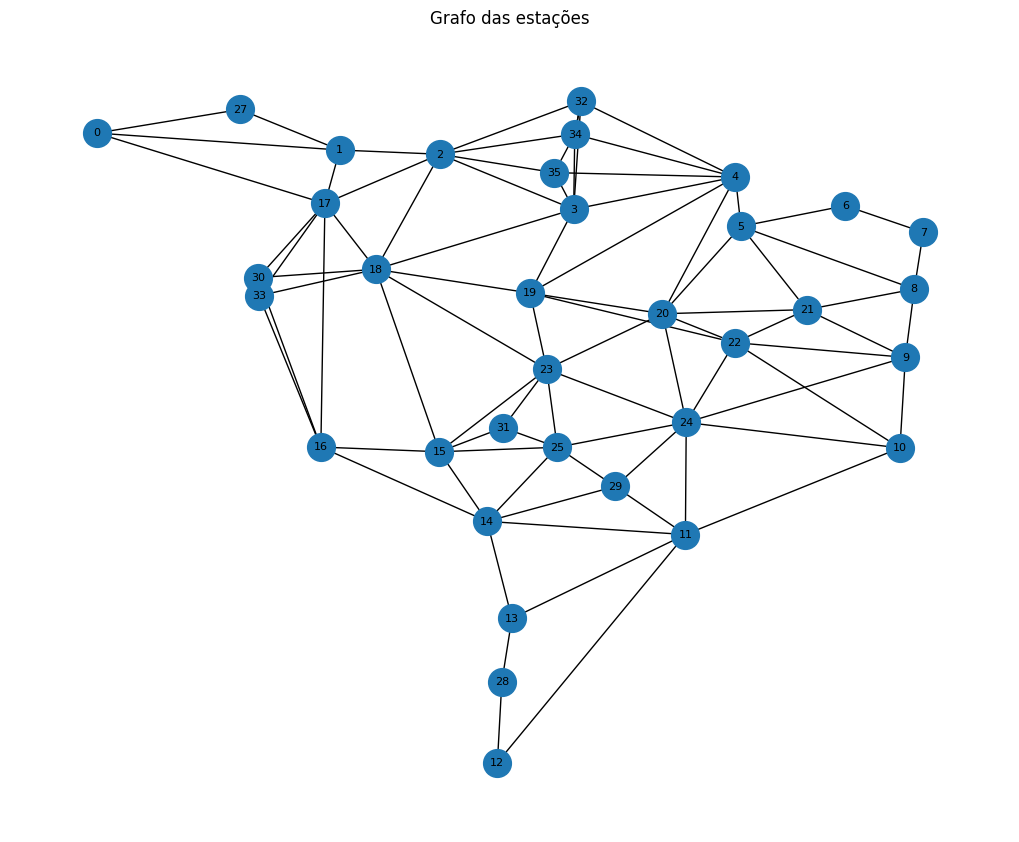

In [3]:

def dms_to_decimal(degrees, minutes, seconds, direction):
    decimal = float(degrees) + float(minutes) / 60 + float(seconds) / 3600
    if str(direction).upper() in ["S", "W", "O"]:
        decimal *= -1
    return decimal

def haversine(lat1, lon1, lat2, lon2):
    R = 6371
    lat1, lon1, lat2, lon2 = map(math.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = math.sin(dlat / 2) ** 2 + math.cos(lat1) * math.cos(lat2) * math.sin(dlon / 2) ** 2
    c = 2 * math.asin(math.sqrt(a))
    return R * c

pos = {n: (float(G.nodes[n]['x']), float(G.nodes[n]['y'])) for n in G.nodes}

plt.figure(figsize=(10, 8))
nx.draw(G, pos, with_labels=True, node_size=400, font_size=8)
plt.title("Grafo das estações")
plt.show()
plt.close()


## 3. Caminhos dos dados e carregamento bruto dos CSVs

In [4]:

PATH_2023 = "/home/viniz0r/Documentos/IT/ESTAÇÕES CGE/estações_meteorológicas_31_CGESP_2016_2024/estações_meteorológicas/meteorologicas_2023/"
PATH_2024 = "/home/viniz0r/Documentos/IT/ESTAÇÕES CGE/estações_meteorológicas_31_CGESP_2016_2024/estações_meteorológicas/meteorologicas_2024/"

def _detectar_sep(caminho_csv: str) -> str:
    with open(caminho_csv, "r", encoding="utf-8", errors="ignore") as f:
        linha = f.readline()
    return ";" if linha.count(";") > linha.count(",") else ","

def carregar_estacoes_sem_agregar(path: str) -> pd.DataFrame:
    arquivos = glob.glob(os.path.join(path, "*.csv"))
    estacoes_processadas = []

    print(f"Iniciando processamento de {len(arquivos)} arquivos em {path}")

    for arq in arquivos:
        id_estacao = os.path.basename(arq).replace(".csv", "")

        sep = _detectar_sep(arq)
        df = pd.read_csv(
            arq,
            sep=sep,
            engine="python",
            encoding="utf-8",
            on_bad_lines="skip"
        )
        df.columns = [c.strip() for c in df.columns]

        if "DATA" not in df.columns:
            possiveis = [c for c in df.columns if c.lower() in ("data", "datetime", "timestamp")]
            if not possiveis:
                raise ValueError(f"CSV {arq} não tem coluna DATA. Colunas: {df.columns.tolist()}")
            df = df.rename(columns={possiveis[0]: "DATA"})

        df["DATA"] = pd.to_datetime(df["DATA"], errors="coerce", dayfirst=True)
        df = df.dropna(subset=["DATA"]).set_index("DATA").sort_index()
        df = df[~df.index.duplicated(keep="first")]

        for col in df.columns:
            if df[col].dtype == "object":
                df[col] = (
                    df[col].astype(str)
                    .str.replace(",", ".", regex=False)
                    .str.strip()
                )
                try:
                    df[col] = pd.to_numeric(df[col], errors="ignore")
                except Exception:
                    pass

        df["station_id"] = id_estacao
        estacoes_processadas.append(df)

    if not estacoes_processadas:
        raise ValueError(f"Nenhum CSV encontrado em {path}")

    df_final = pd.concat(estacoes_processadas).sort_index()
    df_final.index.name = "DATA"
    return df_final

df_2023 = carregar_estacoes_sem_agregar(PATH_2023)
df_2024 = carregar_estacoes_sem_agregar(PATH_2024)

print(f"Total de registros 2023: {len(df_2023)}")
print(f"Total de registros 2024: {len(df_2024)}")
print("Colunas 2023:", df_2023.columns.tolist())
print("Colunas 2024:", df_2024.columns.tolist())


Iniciando processamento de 32 arquivos em /home/viniz0r/Documentos/IT/ESTAÇÕES CGE/estações_meteorológicas_31_CGESP_2016_2024/estações_meteorológicas/meteorologicas_2023/
Iniciando processamento de 32 arquivos em /home/viniz0r/Documentos/IT/ESTAÇÕES CGE/estações_meteorológicas_31_CGESP_2016_2024/estações_meteorológicas/meteorologicas_2024/
Total de registros 2023: 682933
Total de registros 2024: 660316
Colunas 2023: ['Posto', 'Unnamed: 2', 'PLU(mm)', 'Vel.VT(m/s)', 'Dir.VT(o)', 'Temp(oC)', 'Umid.Rel.(%)', 'Pressão(mb)', 'Bateria(V)', 'Rajada.VT(m/s)', 'station_id', 'Sens. Térmica(°C)', 'PressÃ£o(mb)']
Colunas 2024: ['Posto', 'Unnamed: 2', 'PLU(mm)', 'Vel.VT(m/s)', 'Dir.VT(o)', 'Temp(oC)', 'Umid.Rel.(%)', 'Pressão(mb)', 'Bateria(V)', 'Sens. Térmica(°C)', 'Rajada.VT(m/s)', 'station_id', 'PressÃ£o(mb)']


## 4. Montagem robusta do tensor `[tempo, nós, atributos]` com diagnóstico

In [5]:

def normalizar_nome(s):
    s = str(s).lower().strip()
    s = unicodedata.normalize("NFKD", s).encode("ASCII", "ignore").decode("ASCII")
    s = re.sub(r"[^a-z0-9]+", "_", s)
    s = re.sub(r"_+", "_", s).strip("_")
    return s

def _primeira_coluna_existente(df: pd.DataFrame, candidatos: list[str]) -> str:
    normalizadas = {normalizar_nome(c): c for c in df.columns}
    for c in candidatos:
        if c in df.columns:
            return c
    for c in candidatos:
        c_norm = normalizar_nome(c)
        if c_norm in normalizadas:
            return normalizadas[c_norm]
    raise KeyError(f"Nenhuma das colunas {candidatos} existe. Colunas disponíveis: {df.columns.tolist()}")

def encontrar_no_correspondente(nome_arquivo, G):
    nome_norm = normalizar_nome(nome_arquivo)

    correspondencias = []
    for node in G.nodes():
        label = G.nodes[node].get("label", "")
        label_norm = normalizar_nome(label)

        if label_norm and (label_norm in nome_norm or nome_norm in label_norm):
            correspondencias.append(node)
            continue

        partes = [p for p in label_norm.split("_") if len(p) >= 3]
        if any(parte in nome_norm for parte in partes):
            correspondencias.append(node)

    if len(correspondencias) == 1:
        return correspondencias[0]

    if len(correspondencias) > 1:
        return correspondencias[0]

    return None

def preparar_dataset_final_v5(df_input: pd.DataFrame, G, nome_conjunto="dataset"):
    df_fix = df_input.copy()

    col_plu  = _primeira_coluna_existente(df_fix, ["PLU(mm)", "PLU (mm)", "PLU_mm", "pluviosidade(mm)", "Pluviosidade(mm)"])
    col_vel  = _primeira_coluna_existente(df_fix, ["Vel.VT(m/s)", "VEL(m/s)", "VEL", "Velocidade(m/s)"])
    col_temp = _primeira_coluna_existente(df_fix, ["Sens. Térmica(°C)", "Sens. Termica(°C)", "Temp(oC)", "Temp(°C)", "Temperatura(°C)"])

    col_umid = None
    for cand in ["Umid.Rel(%)", "Umid Rel(%)", "Umidade(%)", "UMID(%)", "Umidade Relativa(%)"]:
        try:
            col_umid = _primeira_coluna_existente(df_fix, [cand])
            break
        except KeyError:
            continue

    print(f"\\n[{nome_conjunto}] Colunas escolhidas:")
    print("PLU  ->", col_plu)
    print("TEMP ->", col_temp)
    print("UMID ->", col_umid if col_umid is not None else "não encontrada")
    print("VEL  ->", col_vel)

    df_fix["PLU_real"] = pd.to_numeric(df_fix[col_plu], errors="coerce").fillna(0)
    df_fix["VEL_real"] = pd.to_numeric(df_fix[col_vel], errors="coerce").fillna(0)

    df_fix["TEMP_real"] = pd.to_numeric(df_fix[col_temp], errors="coerce")
    temp_media = df_fix["TEMP_real"].mean()
    if pd.isna(temp_media):
        temp_media = 0.0
    df_fix["TEMP_real"] = df_fix["TEMP_real"].fillna(temp_media)

    if col_umid is not None:
        df_fix["UMID_real"] = pd.to_numeric(df_fix[col_umid], errors="coerce")
        umid_media = df_fix["UMID_real"].mean()
        if pd.isna(umid_media):
            umid_media = 0.0
        df_fix["UMID_real"] = df_fix["UMID_real"].fillna(umid_media)
    else:
        df_fix["UMID_real"] = 0.0

    df_fix["node_id"] = df_fix["station_id"].apply(lambda s: encontrar_no_correspondente(s, G))

    print(f"\\n[{nome_conjunto}] Total de linhas antes do dropna: {len(df_fix)}")
    sem_no = df_fix["node_id"].isna().sum()
    print(f"[{nome_conjunto}] Linhas sem node_id: {sem_no}")

    if sem_no > 0:
        estacoes_sem_no = df_fix.loc[df_fix["node_id"].isna(), "station_id"].drop_duplicates().tolist()
        print(f"[{nome_conjunto}] Estações sem correspondência no grafo:")
        for est in estacoes_sem_no:
            print("  -", est)

    df_fix = df_fix.dropna(subset=["node_id"]).copy()
    df_fix["node_id"] = df_fix["node_id"].astype(str)

    features = ["PLU_real", "TEMP_real", "UMID_real", "VEL_real"]
    nodes_lista = list(G.nodes())

    df_pivot = (
        df_fix.reset_index()
        .pivot_table(
            index="DATA",
            columns="node_id",
            values=features,
            aggfunc="mean"
        )
        .sort_index()
    )

    df_pivot = df_pivot.reindex(
        columns=pd.MultiIndex.from_product([features, nodes_lista]),
        fill_value=np.nan
    )

    for feat in features:
        bloco = df_pivot[feat]
        nos_todos_nan = bloco.columns[bloco.isna().all()].tolist()
        if nos_todos_nan:
            print(f"[ALERTA][{nome_conjunto}] Nós totalmente vazios para {feat}: {nos_todos_nan}")

    df_pivot = df_pivot.interpolate(method="time", limit_direction="both")
    df_pivot = df_pivot.ffill().bfill()

    for feat in features:
        bloco = df_pivot[feat]
        nos_todos_nan = bloco.columns[bloco.isna().all()].tolist()
        if nos_todos_nan:
            print(f"[ALERTA][{nome_conjunto}] Após interpolação ainda vazios em {feat}: {nos_todos_nan}")

    df_pivot = df_pivot.fillna(0)

    data_3d = (
        df_pivot.values
        .reshape(len(df_pivot), len(features), len(nodes_lista))
        .transpose(0, 2, 1)
    )

    X = torch.tensor(data_3d, dtype=torch.float32).to(DEVICE)
    return X, df_pivot.index, df_fix, df_pivot

X_2023, timestamps_2023, df_fix_2023, df_pivot_2023 = preparar_dataset_final_v5(df_2023, G, nome_conjunto="2023")
X_2024, timestamps_2024, df_fix_2024, df_pivot_2024 = preparar_dataset_final_v5(df_2024, G, nome_conjunto="2024")

print("\\nShapes finais:")
print("X_2023:", X_2023.shape)
print("X_2024:", X_2024.shape)
print("Primeiros timestamps 2023:", list(timestamps_2023[:5]))
print("Primeiros timestamps 2024:", list(timestamps_2024[:5]))


\n[2023] Colunas escolhidas:
PLU  -> PLU(mm)
TEMP -> Sens. Térmica(°C)
UMID -> Umid.Rel.(%)
VEL  -> Vel.VT(m/s)
\n[2023] Total de linhas antes do dropna: 682933
[2023] Linhas sem node_id: 0
[ALERTA][2023] Nós totalmente vazios para PLU_real: ['3', '7', '14', '20', '21', '22', '23', '24', '25', '27', '28', '29', '30', '31', '32', '33', '34', '35']
[ALERTA][2023] Nós totalmente vazios para TEMP_real: ['3', '7', '14', '20', '21', '22', '23', '24', '25', '27', '28', '29', '30', '31', '32', '33', '34', '35']
[ALERTA][2023] Nós totalmente vazios para UMID_real: ['3', '7', '14', '20', '21', '22', '23', '24', '25', '27', '28', '29', '30', '31', '32', '33', '34', '35']
[ALERTA][2023] Nós totalmente vazios para VEL_real: ['3', '7', '14', '20', '21', '22', '23', '24', '25', '27', '28', '29', '30', '31', '32', '33', '34', '35']
[ALERTA][2023] Após interpolação ainda vazios em PLU_real: ['3', '7', '14', '20', '21', '22', '23', '24', '25', '27', '28', '29', '30', '31', '32', '33', '34', '35']
[ALERT

## 5. Separação treino/teste para pluviosidade e temperatura

In [6]:

TARGET_IDX_PLU = 0
TARGET_IDX_TEMP = 1

# chuva
Y_2023 = X_2023[1:, :, TARGET_IDX_PLU]
X_2023_final = X_2023[:-1, :, :]
Y_2024 = X_2024[1:, :, TARGET_IDX_PLU]
X_2024_final = X_2024[:-1, :, :]

X_train, Y_train = X_2023_final, Y_2023
X_test, Y_test = X_2024_final, Y_2024

# temperatura
Y_2023_temp = X_2023[1:, :, TARGET_IDX_TEMP]
X_2023_temp = X_2023[:-1, :, :]
Y_2024_temp = X_2024[1:, :, TARGET_IDX_TEMP]
X_2024_temp = X_2024[:-1, :, :]

X_train_temp, Y_train_temp = X_2023_temp, Y_2023_temp
X_test_temp, Y_test_temp = X_2024_temp, Y_2024_temp

print("Chuva:")
print("X_train:", X_train.shape, "| Y_train:", Y_train.shape)
print("X_test :", X_test.shape,  "| Y_test :", Y_test.shape)

print("\\nTemperatura:")
print("X_train_temp:", X_train_temp.shape, "| Y_train_temp:", Y_train_temp.shape)
print("X_test_temp :", X_test_temp.shape,  "| Y_test_temp :", Y_test_temp.shape)

Chuva:
X_train: torch.Size([41705, 35, 4]) | Y_train: torch.Size([41705, 35])
X_test : torch.Size([41356, 35, 4]) | Y_test : torch.Size([41356, 35])
\nTemperatura:
X_train_temp: torch.Size([41705, 35, 4]) | Y_train_temp: torch.Size([41705, 35])
X_test_temp : torch.Size([41356, 35, 4]) | Y_test_temp : torch.Size([41356, 35])


## 6. Grafo DGL e teste rápido

In [7]:

g_dgl = dgl.from_networkx(G).to(DEVICE)

conv = dglnn.SAGEConv(4, 16, aggregator_type="mean").to(DEVICE)
primeira_hora = X_train[0]
saida = conv(g_dgl, primeira_hora)

print("Entrada:", primeira_hora.shape)
print("Saída :", saida.shape)

Entrada: torch.Size([35, 4])
Saída : torch.Size([35, 16])


## 7. Modelo GraphSAGE

In [8]:

class MeteorologiaGNN(nn.Module):
    def __init__(self, in_feats, h_feats):
        super().__init__()
        self.conv1 = SAGEConv(in_feats, h_feats, aggregator_type="mean")
        self.conv2 = SAGEConv(h_feats, 1, aggregator_type="mean")

    def forward(self, g, in_feat):
        h = self.conv1(g, in_feat)
        h = F.relu(h)
        h = self.conv2(g, h)
        return h.squeeze()

print(MeteorologiaGNN(in_feats=4, h_feats=32))

MeteorologiaGNN(
  (conv1): SAGEConv(
    (feat_drop): Dropout(p=0.0, inplace=False)
    (fc_neigh): Linear(in_features=4, out_features=32, bias=False)
    (fc_self): Linear(in_features=4, out_features=32, bias=True)
  )
  (conv2): SAGEConv(
    (feat_drop): Dropout(p=0.0, inplace=False)
    (fc_neigh): Linear(in_features=32, out_features=1, bias=False)
    (fc_self): Linear(in_features=32, out_features=1, bias=True)
  )
)


## 8. Função única de treino

In [9]:

def treinar_modelo(
    X_train,
    Y_train,
    g_dgl,
    in_feats=4,
    h_feats=32,
    lr=0.001,
    max_epochs=20,
    target_loss=1e-4,
    min_delta=1e-6,
    patience=2,
    nome_modelo="modelo"
):
    modelo = MeteorologiaGNN(in_feats=in_feats, h_feats=h_feats).to(DEVICE)
    optimizer = torch.optim.Adam(modelo.parameters(), lr=lr)
    criterion = nn.MSELoss()

    best_loss = float("inf")
    no_improve = 0
    best_state = None
    historico_loss = []

    modelo.train()
    for epoch in range(1, max_epochs + 1):
        total_loss = 0.0

        for i in range(len(X_train)):
            pred = modelo(g_dgl, X_train[i])
            loss = criterion(pred, Y_train[i])

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += float(loss.item())

        epoch_loss = total_loss / len(X_train)
        historico_loss.append(epoch_loss)

        print(f"{nome_modelo} | Época {epoch:4d} | Erro treino: {epoch_loss:.8f}")

        if epoch_loss <= target_loss:
            print(f"{nome_modelo} | Parando: erro <= {target_loss} (erro={epoch_loss:.8f})")
            best_state = deepcopy(modelo.state_dict())
            break

        if best_loss - epoch_loss > min_delta:
            best_loss = epoch_loss
            no_improve = 0
            best_state = deepcopy(modelo.state_dict())
        else:
            no_improve += 1
            if no_improve >= patience:
                print(
                    f"{nome_modelo} | Parando: melhora < {min_delta} por {patience} épocas seguidas. "
                    f"best={best_loss:.8f}, atual={epoch_loss:.8f}"
                )
                break

    if best_state is not None:
        modelo.load_state_dict(best_state)

    return modelo, historico_loss

## 9. Treino do modelo de pluviosidade

In [10]:

modelo, historico_loss = treinar_modelo(
    X_train=X_train,
    Y_train=Y_train,
    g_dgl=g_dgl,
    in_feats=4,
    h_feats=32,
    lr=0.001,
    max_epochs=20,
    target_loss=1e-4,
    min_delta=1e-6,
    patience=2,
    nome_modelo="Pluviosidade"
)

Pluviosidade | Época    1 | Erro treino: 111.45231880
Pluviosidade | Época    2 | Erro treino: 0.35141196
Pluviosidade | Época    3 | Erro treino: 0.31720531
Pluviosidade | Época    4 | Erro treino: 0.29814627
Pluviosidade | Época    5 | Erro treino: 0.28886798
Pluviosidade | Época    6 | Erro treino: 0.27991182
Pluviosidade | Época    7 | Erro treino: 0.27809045
Pluviosidade | Época    8 | Erro treino: 0.27388267
Pluviosidade | Época    9 | Erro treino: 0.26580462
Pluviosidade | Época   10 | Erro treino: 0.25689864
Pluviosidade | Época   11 | Erro treino: 0.25014364
Pluviosidade | Época   12 | Erro treino: 0.23914296
Pluviosidade | Época   13 | Erro treino: 0.22987602
Pluviosidade | Época   14 | Erro treino: 0.22228863
Pluviosidade | Época   15 | Erro treino: 0.21486085
Pluviosidade | Época   16 | Erro treino: 0.20525438
Pluviosidade | Época   17 | Erro treino: 0.19657553
Pluviosidade | Época   18 | Erro treino: 0.19149045
Pluviosidade | Época   19 | Erro treino: 0.18265846
Pluviosida

## 10. Treino do modelo de temperatura

In [11]:

modelo_temp, historico_loss_temp = treinar_modelo(
    X_train=X_train_temp,
    Y_train=Y_train_temp,
    g_dgl=g_dgl,
    in_feats=4,
    h_feats=32,
    lr=0.001,
    max_epochs=20,
    target_loss=1e-4,
    min_delta=1e-6,
    patience=2,
    nome_modelo="Temperatura"
)


Temperatura | Época    1 | Erro treino: 7.46667196
Temperatura | Época    2 | Erro treino: 0.14070438
Temperatura | Época    3 | Erro treino: 0.12148158
Temperatura | Época    4 | Erro treino: 0.10388899
Temperatura | Época    5 | Erro treino: 0.09065725
Temperatura | Época    6 | Erro treino: 0.08196630
Temperatura | Época    7 | Erro treino: 0.07427365
Temperatura | Época    8 | Erro treino: 0.06669636
Temperatura | Época    9 | Erro treino: 0.06016482
Temperatura | Época   10 | Erro treino: 0.05464944
Temperatura | Época   11 | Erro treino: 0.04939418
Temperatura | Época   12 | Erro treino: 0.04482147
Temperatura | Época   13 | Erro treino: 0.04107555
Temperatura | Época   14 | Erro treino: 0.03772191
Temperatura | Época   15 | Erro treino: 0.03427121
Temperatura | Época   16 | Erro treino: 0.03102506
Temperatura | Época   17 | Erro treino: 0.02793174
Temperatura | Época   18 | Erro treino: 0.02541389
Temperatura | Época   19 | Erro treino: 0.02367192
Temperatura | Época   20 | Erro

## 11. Curvas de perda

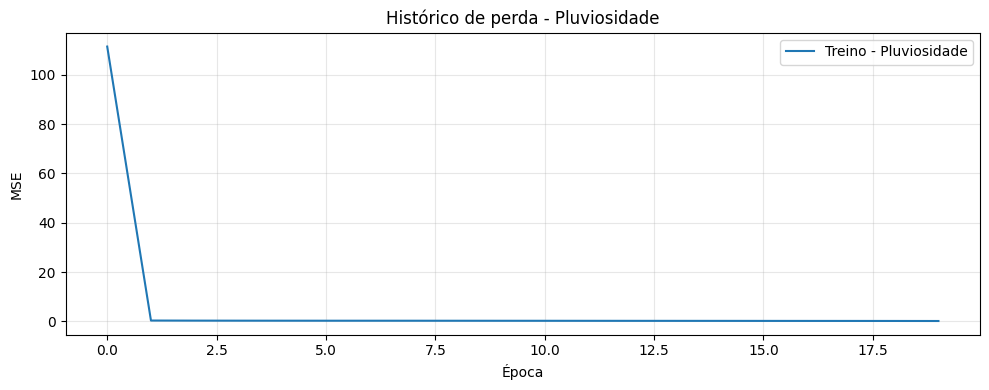

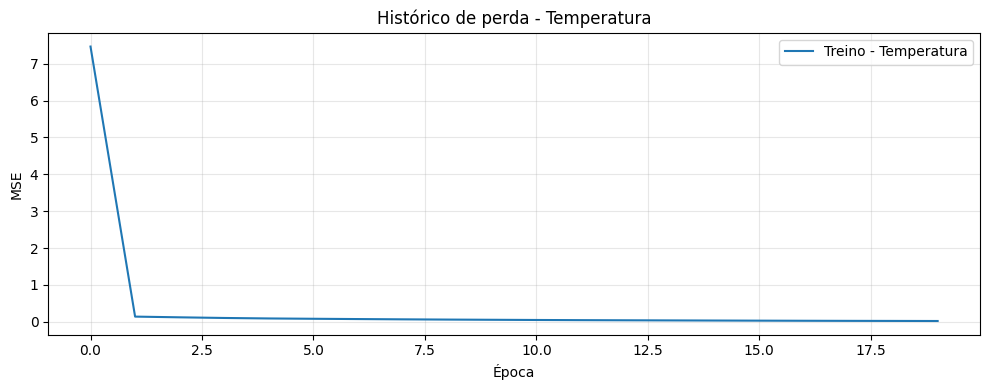

In [12]:

plt.figure(figsize=(10, 4))
plt.plot(historico_loss, label="Treino - Pluviosidade")
plt.xlabel("Época")
plt.ylabel("MSE")
plt.title("Histórico de perda - Pluviosidade")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()
plt.close()

plt.figure(figsize=(10, 4))
plt.plot(historico_loss_temp, label="Treino - Temperatura")
plt.xlabel("Época")
plt.ylabel("MSE")
plt.title("Histórico de perda - Temperatura")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()
plt.close()

## 12. Função única para avaliar e plotar todos os nós

In [13]:

def avaliar_e_plotar_todos_nos(
    modelo,
    g_dgl,
    X_test,
    Y_test,
    timestamps_2024,
    nome_variavel="Chuva",
    ylabel="Valor",
    criterio_janela="pico_real",
    window=120,
    salvar=True,
    mostrar=True,
    pasta_saida="graficos"
):
    modelo.eval()
    half_window = window // 2

    preds_all = []
    trues_all = []

    with torch.no_grad():
        for i in range(len(X_test)):
            pred = modelo(g_dgl, X_test[i])

            y_pred = pred.detach().cpu().numpy().reshape(-1)
            y_true = Y_test[i].detach().cpu().numpy().reshape(-1)

            preds_all.append(y_pred)
            trues_all.append(y_true)

    preds_all = np.array(preds_all)
    trues_all = np.array(trues_all)

    num_nos = preds_all.shape[1]
    tempo_2024 = np.array(timestamps_2024[1:])
    resultados = []

    pasta_variavel = os.path.join(pasta_saida, nome_variavel.lower().replace(" ", "_"))
    if salvar:
        os.makedirs(pasta_variavel, exist_ok=True)

    for node_id in range(num_nos):
        preds_no = preds_all[:, node_id]
        trues_no = trues_all[:, node_id]

        if criterio_janela == "pico_real":
            idx_central = int(np.argmax(trues_no))
        elif criterio_janela == "maior_desvio_media":
            idx_central = int(np.argmax(np.abs(trues_no - np.mean(trues_no))))
        else:
            raise ValueError("criterio_janela deve ser 'pico_real' ou 'maior_desvio_media'")

        start = max(0, idx_central - half_window)
        end = min(len(trues_no), idx_central + half_window)

        mae = float(np.mean(np.abs(preds_no - trues_no)))
        rmse = float(np.sqrt(np.mean((preds_no - trues_no) ** 2)))

        plt.figure(figsize=(12, 5))
        plt.plot(
            tempo_2024[start:end],
            trues_no[start:end],
            linewidth=2,
            label="Real (2024)"
        )
        plt.plot(
            tempo_2024[start:end],
            preds_no[start:end],
            linewidth=2,
            label="Previsto (modelo treinado em 2023)"
        )
        plt.xlabel("Tempo")
        plt.ylabel(ylabel)
        plt.title(f"Evolução temporal de {nome_variavel.lower()} — nó {node_id} em 2024")
        plt.legend()
        plt.xticks(rotation=30)
        plt.grid(alpha=0.3)
        plt.tight_layout()

        if salvar:
            nome_arquivo = os.path.join(
                pasta_variavel,
                f"{nome_variavel.lower().replace(' ', '_')}_no_{node_id}.png"
            )
            plt.savefig(nome_arquivo, dpi=150, bbox_inches="tight")

        if mostrar:
            plt.show()
        plt.close()

        print(
            f"Nó {node_id} | {nome_variavel} | "
            f"MAE = {mae:.6f} | RMSE = {rmse:.6f} | Janela: {start} até {end}"
        )

        resultados.append({
            "no": node_id,
            "variavel": nome_variavel,
            "mae": mae,
            "rmse": rmse,
            "idx_central": idx_central,
            "start": start,
            "end": end,
        })

    return pd.DataFrame(resultados), preds_all, trues_all


## 13. Avaliação de pluviosidade em todos os nós

In [14]:

df_resultados_chuva, preds_chuva_all, trues_chuva_all = avaliar_e_plotar_todos_nos(
    modelo=modelo,
    g_dgl=g_dgl,
    X_test=X_test,
    Y_test=Y_test,
    timestamps_2024=timestamps_2024,
    nome_variavel="Pluviosidade",
    ylabel="Chuva",
    criterio_janela="pico_real",
    window=120,
    salvar=True,
    mostrar=False,
    pasta_saida="graficos_2024"
)

df_resultados_chuva.sort_values("rmse").head(10)


Nó 0 | Pluviosidade | MAE = 0.679004 | RMSE = 0.830401 | Janela: 27712 até 27832
Nó 1 | Pluviosidade | MAE = 1.586587 | RMSE = 2.018389 | Janela: 6209 até 6329
Nó 2 | Pluviosidade | MAE = 1.924351 | RMSE = 2.451614 | Janela: 12486 até 12606
Nó 3 | Pluviosidade | MAE = 0.406477 | RMSE = 0.510721 | Janela: 0 até 60
Nó 4 | Pluviosidade | MAE = 0.577205 | RMSE = 0.676146 | Janela: 6197 até 6317
Nó 5 | Pluviosidade | MAE = 0.380613 | RMSE = 0.476748 | Janela: 10842 até 10962
Nó 6 | Pluviosidade | MAE = 0.062379 | RMSE = 0.069735 | Janela: 0 até 60
Nó 7 | Pluviosidade | MAE = 0.059324 | RMSE = 0.074680 | Janela: 0 até 60
Nó 8 | Pluviosidade | MAE = 0.055229 | RMSE = 0.068660 | Janela: 0 até 60
Nó 9 | Pluviosidade | MAE = 0.347197 | RMSE = 0.427252 | Janela: 24552 até 24672
Nó 10 | Pluviosidade | MAE = 0.466612 | RMSE = 0.605199 | Janela: 23690 até 23810
Nó 11 | Pluviosidade | MAE = 0.484048 | RMSE = 0.591519 | Janela: 37250 até 37370
Nó 12 | Pluviosidade | MAE = 0.575662 | RMSE = 0.631999 | 

,no,variavel,mae,rmse,idx_central,start,end
8,8,Pluviosidade,0.055229,0.068660,0,0,60
6,6,Pluviosidade,0.062379,0.069735,0,0,60
7,7,Pluviosidade,0.059324,0.074680,0,0,60
18,18,Pluviosidade,0.066696,0.080250,0,0,60
22,22,Pluviosidade,0.086179,0.106954,0,0,60
21,21,Pluviosidade,0.131937,0.133398,0,0,60
23,23,Pluviosidade,0.110993,0.138042,0,0,60
28,28,Pluviosidade,0.122798,0.152653,0,0,60
17,17,Pluviosidade,0.308005,0.388637,0,0,60
9,9,Pluviosidade,0.347197,0.427252,24612,24552,24672


## 14. Avaliação de temperatura em todos os nós

In [15]:

df_resultados_temp, preds_temp_all, trues_temp_all = avaliar_e_plotar_todos_nos(
    modelo=modelo_temp,
    g_dgl=g_dgl,
    X_test=X_test_temp,
    Y_test=Y_test_temp,
    timestamps_2024=timestamps_2024,
    nome_variavel="Temperatura",
    ylabel="Temperatura / Sens. Térmica (°C)",
    criterio_janela="maior_desvio_media",
    window=120,
    salvar=True,
    mostrar=False,
    pasta_saida="graficos_2024"
)

df_resultados_temp.sort_values("rmse").head(10)


Nó 0 | Temperatura | MAE = 0.559220 | RMSE = 0.728138 | Janela: 37250 até 37370
Nó 1 | Temperatura | MAE = 0.409425 | RMSE = 0.653465 | Janela: 0 até 60
Nó 2 | Temperatura | MAE = 2.130297 | RMSE = 2.384122 | Janela: 0 até 60
Nó 3 | Temperatura | MAE = 0.827109 | RMSE = 0.985663 | Janela: 0 até 60
Nó 4 | Temperatura | MAE = 0.390629 | RMSE = 0.390992 | Janela: 0 até 60
Nó 5 | Temperatura | MAE = 0.482762 | RMSE = 0.495387 | Janela: 0 até 60
Nó 6 | Temperatura | MAE = 0.043043 | RMSE = 0.051450 | Janela: 0 até 60
Nó 7 | Temperatura | MAE = 0.205779 | RMSE = 0.223685 | Janela: 0 até 60
Nó 8 | Temperatura | MAE = 0.178743 | RMSE = 0.178892 | Janela: 0 até 60
Nó 9 | Temperatura | MAE = 0.426351 | RMSE = 0.448611 | Janela: 0 até 60
Nó 10 | Temperatura | MAE = 0.383603 | RMSE = 0.385006 | Janela: 0 até 60
Nó 11 | Temperatura | MAE = 0.381128 | RMSE = 0.391472 | Janela: 0 até 60
Nó 12 | Temperatura | MAE = 0.450325 | RMSE = 0.468431 | Janela: 0 até 60
Nó 13 | Temperatura | MAE = 0.576302 | RM

,no,variavel,mae,rmse,idx_central,start,end
6,6,Temperatura,0.043043,0.051450,0,0,60
21,21,Temperatura,0.053265,0.053443,0,0,60
18,18,Temperatura,0.154013,0.177062,0,0,60
8,8,Temperatura,0.178743,0.178892,0,0,60
28,28,Temperatura,0.219144,0.219347,0,0,60
7,7,Temperatura,0.205779,0.223685,0,0,60
20,20,Temperatura,0.197813,0.225051,0,0,60
22,22,Temperatura,0.269855,0.270304,0,0,60
23,23,Temperatura,0.272628,0.272772,0,0,60
25,25,Temperatura,0.299583,0.300901,0,0,60


## 15. Resumo das métricas

In [16]:

print("Melhores nós - Pluviosidade")
display(df_resultados_chuva.sort_values("rmse").head(10))

print("\\nPiores nós - Pluviosidade")
display(df_resultados_chuva.sort_values("rmse", ascending=False).head(10))

print("\\nMelhores nós - Temperatura")
display(df_resultados_temp.sort_values("rmse").head(10))

print("\\nPiores nós - Temperatura")
display(df_resultados_temp.sort_values("rmse", ascending=False).head(10))

Melhores nós - Pluviosidade


,no,variavel,mae,rmse,idx_central,start,end
8,8,Pluviosidade,0.055229,0.068660,0,0,60
6,6,Pluviosidade,0.062379,0.069735,0,0,60
7,7,Pluviosidade,0.059324,0.074680,0,0,60
18,18,Pluviosidade,0.066696,0.080250,0,0,60
22,22,Pluviosidade,0.086179,0.106954,0,0,60
21,21,Pluviosidade,0.131937,0.133398,0,0,60
23,23,Pluviosidade,0.110993,0.138042,0,0,60
28,28,Pluviosidade,0.122798,0.152653,0,0,60
17,17,Pluviosidade,0.308005,0.388637,0,0,60
9,9,Pluviosidade,0.347197,0.427252,24612,24552,24672


\nPiores nós - Pluviosidade


,no,variavel,mae,rmse,idx_central,start,end
32,32,Pluviosidade,4.351859,7.028852,19707,19647,19767
30,30,Pluviosidade,4.891501,5.085564,31210,31150,31270
31,31,Pluviosidade,3.155207,3.406042,0,0,60
20,20,Pluviosidade,2.263566,2.864949,6257,6197,6317
2,2,Pluviosidade,1.924351,2.451614,12546,12486,12606
1,1,Pluviosidade,1.586587,2.018389,6269,6209,6329
19,19,Pluviosidade,1.464669,1.967013,34378,34318,34438
33,33,Pluviosidade,1.534610,1.666355,0,0,60
14,14,Pluviosidade,1.488045,1.555978,0,0,60
29,29,Pluviosidade,1.105984,1.157974,0,0,60


\nMelhores nós - Temperatura


,no,variavel,mae,rmse,idx_central,start,end
6,6,Temperatura,0.043043,0.051450,0,0,60
21,21,Temperatura,0.053265,0.053443,0,0,60
18,18,Temperatura,0.154013,0.177062,0,0,60
8,8,Temperatura,0.178743,0.178892,0,0,60
28,28,Temperatura,0.219144,0.219347,0,0,60
7,7,Temperatura,0.205779,0.223685,0,0,60
20,20,Temperatura,0.197813,0.225051,0,0,60
22,22,Temperatura,0.269855,0.270304,0,0,60
23,23,Temperatura,0.272628,0.272772,0,0,60
25,25,Temperatura,0.299583,0.300901,0,0,60


\nPiores nós - Temperatura


,no,variavel,mae,rmse,idx_central,start,end
31,31,Temperatura,4.147485,6.195691,0,0,60
33,33,Temperatura,2.053363,3.103056,0,0,60
2,2,Temperatura,2.130297,2.384122,0,0,60
30,30,Temperatura,1.724467,2.006261,0,0,60
19,19,Temperatura,1.000907,1.441572,0,0,60
34,34,Temperatura,0.966500,1.167151,0,0,60
3,3,Temperatura,0.827109,0.985663,0,0,60
14,14,Temperatura,0.791195,0.956143,0,0,60
15,15,Temperatura,0.739335,0.953911,0,0,60
32,32,Temperatura,0.659116,0.778257,0,0,60


## 16. Gráfico individual opcional para um nó específico

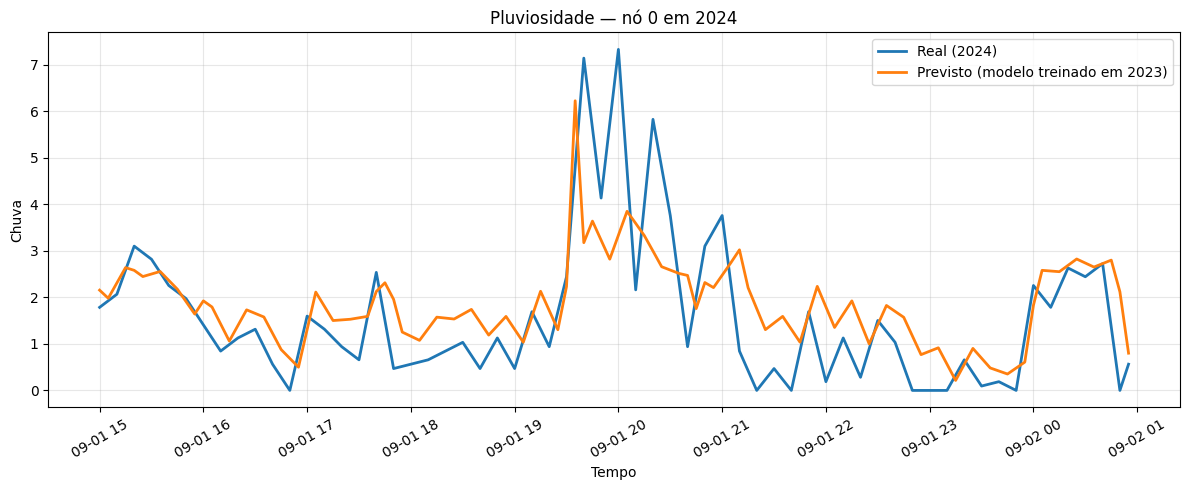

Nó 0 | Pluviosidade | MAE = 0.679004 | RMSE = 0.830401


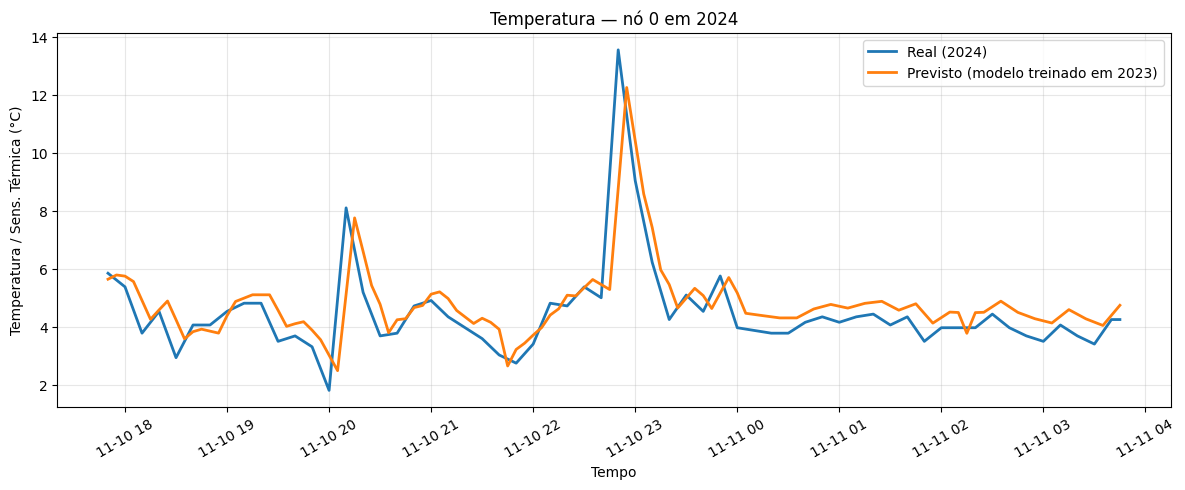

Nó 0 | Temperatura | MAE = 0.559220 | RMSE = 0.728138


In [20]:

def plotar_no_especifico(preds_all, trues_all, timestamps_2024, node_id, nome_variavel, ylabel, criterio_janela="pico_real", window=120):
    preds_no = preds_all[:, node_id]
    trues_no = trues_all[:, node_id]
    half_window = window // 2

    if criterio_janela == "pico_real":
        idx_central = int(np.argmax(trues_no))
    else:
        idx_central = int(np.argmax(np.abs(trues_no - np.mean(trues_no))))

    start = max(0, idx_central - half_window)
    end = min(len(trues_no), idx_central + half_window)
    tempo_2024 = np.array(timestamps_2024[1:])

    mae = float(np.mean(np.abs(preds_no - trues_no)))
    rmse = float(np.sqrt(np.mean((preds_no - trues_no) ** 2)))

    plt.figure(figsize=(12, 5))
    plt.plot(tempo_2024[start:end], trues_no[start:end], linewidth=2, label="Real (2024)")
    plt.plot(tempo_2024[start:end], preds_no[start:end], linewidth=2, label="Previsto (modelo treinado em 2023)")
    plt.xlabel("Tempo")
    plt.ylabel(ylabel)
    plt.title(f"{nome_variavel} — nó {node_id} em 2024")
    plt.legend()
    plt.xticks(rotation=30)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    plt.close()

    print(f"Nó {node_id} | {nome_variavel} | MAE = {mae:.6f} | RMSE = {rmse:.6f}")

# exemplo:
plotar_no_especifico(preds_chuva_all, trues_chuva_all, timestamps_2024, node_id=0, nome_variavel="Pluviosidade", ylabel="Chuva")
plotar_no_especifico(preds_temp_all, trues_temp_all, timestamps_2024, node_id=0, nome_variavel="Temperatura", ylabel="Temperatura / Sens. Térmica (°C)", criterio_janela="maior_desvio_media")